# Using SIMPLEOmics to integrate multi-slice spatial RNA-ATAC data of mouse brain

## 1. Load packages

In [ ]:
import warnings
warnings.filterwarnings("ignore")
import SIMPLEOmics

# the location of R (used for the mclust clustering)
import os
os.environ['R_HOME'] = "/home/lvyz/miniconda3/envs/SIMPLEOmics_env/lib/R"
os.environ['R_USER'] = "/home/lvyz/miniconda3/envs/SIMPLEOmics_env/lib/python3.8/site-packages/rpy2"
from scipy.sparse import block_diag

import scanpy as sc
import pandas as pd
import numpy as np
from scipy.sparse import csr_matrix
import torch
used_device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print(torch.cuda.is_available())

# set seed
seed=2026
SIMPLEOmics.ST_utils.fix_seed(seed)

import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Arial"
plt.rcParams.update({
    "font.family": "Arial",
    "svg.fonttype": "none"
})

True


## 2. Load data and preprocessing for training

In [ ]:
#load data
n_cluster=14
file_folds = ['/data_SIMPLEOmics/Mouse_brain_E15_S1/','/data_SIMPLEOmics/Mouse_brain_E18_S1/']  #please replace 'file_fold' with the download path
name = ["Mouse_Brain_E15_S1","Mouse_Brain_E18_S1"]

edge_index_rna_list = []
edge_index_atac_list = []
offset_rna = 0
offset_atac = 0
rna_adatas = {}
atac_adatas = {}
for file_fold, name in zip(file_folds, name):
    adata_omics1 = sc.read_h5ad(file_fold + 'adata_RNA.h5ad')
    adata_omics2 = sc.read_h5ad(file_fold + 'adata_ATAC.h5ad')
    adata_omics1.obs["anno"]=pd.read_csv(file_fold+"anno.csv",index_col=0)["cluster"]
    adata_omics2.obs["anno"]=pd.read_csv(file_fold+"anno.csv",index_col=0)["cluster"]
    adata_omics1.var_names_make_unique()
    adata_omics2.var_names_make_unique()

    adata_omics1=SIMPLEOmics.Cal_Net(adata_omics1)
    adata_omics2=SIMPLEOmics.Cal_Net(adata_omics2)
    rna_adatas[name] = adata_omics1.copy()
    atac_adatas[name] = adata_omics2.copy()
    edge_index_rna = adata_omics1.uns['edge_index']
    edge_index_rna = edge_index_rna + offset_rna
    offset_rna += adata_omics1.n_obs
    edge_index_rna_list.append(edge_index_rna)
    edge_index_atac = adata_omics2.uns['edge_index']
    edge_index_atac = edge_index_atac + offset_atac
    offset_atac += adata_omics2.n_obs
    edge_index_atac_list.append(edge_index_atac)

adata_rna=sc.concat(rna_adatas, label="batch",index_unique="_")
adata_atac=sc.concat(atac_adatas, label="batch",index_unique="_")
edge_index_rna_concat = np.hstack(edge_index_rna_list)
adata_rna.uns['edge_index'] = edge_index_rna_concat
adata_rna.uns['adj']  = block_diag([i.uns["adj"] for i in rna_adatas.values()])
edge_index_atac_concat = np.hstack(edge_index_atac_list)
adata_atac.uns['edge_index'] = edge_index_atac_concat
adata_atac.uns['adj']  = block_diag([i.uns["adj"] for i in atac_adatas.values()])

# RNA
if isinstance(adata_rna.X, np.ndarray):
    adata_rna.X = csr_matrix(adata_rna.X)
sc.pp.filter_genes(adata_rna, min_cells=10)
sc.pp.highly_variable_genes(adata_rna, flavor="seurat_v3", n_top_genes=5000)
sc.pp.normalize_total(adata_rna, target_sum=1e4)
sc.pp.log1p(adata_rna)
sc.pp.scale(adata_rna)
adata_rna =  adata_rna[:, adata_rna.var['highly_variable']]
adata_rna.obsm["feat"] = SIMPLEOmics.ST_utils.pca(adata_rna, n_comps=60,random_state=seed)
SIMPLEOmics.harmony(adata_rna,feature_labels='feat',batch_labels="batch")

# ATAC
from muon import atac as ac
ac.pp.tfidf(adata_atac, scale_factor=1e4)
sc.pp.normalize_per_cell(adata_atac, counts_per_cell_after=1e4)
sc.pp.log1p(adata_atac)
adata_atac.obsm["feat"] = SIMPLEOmics.ST_utils.pca(adata_atac,n_comps=60,random_state=seed)
SIMPLEOmics.harmony(adata_atac,feature_labels='feat',batch_labels="batch")


------Calculating Spatial Graph (k=6, metric=euclidean)...
Spatial edges: 11694
------Calculating Spatial Graph (k=6, metric=euclidean)...
Spatial edges: 11694
------Calculating Spatial Graph (k=6, metric=euclidean)...
Spatial edges: 12774
------Calculating Spatial Graph (k=6, metric=euclidean)...
Spatial edges: 12774
Use GPU mode.
	Initialization is completed.
	Completed 1 / 20 iteration(s).
	Completed 2 / 20 iteration(s).
	Completed 3 / 20 iteration(s).
	Completed 4 / 20 iteration(s).
	Completed 5 / 20 iteration(s).
	Completed 6 / 20 iteration(s).
	Completed 7 / 20 iteration(s).
	Completed 8 / 20 iteration(s).
Reach convergence after 8 iteration(s).
Use GPU mode.
	Initialization is completed.
	Completed 1 / 20 iteration(s).
	Completed 2 / 20 iteration(s).
	Completed 3 / 20 iteration(s).
	Completed 4 / 20 iteration(s).
	Completed 5 / 20 iteration(s).
	Completed 6 / 20 iteration(s).
	Completed 7 / 20 iteration(s).
	Completed 8 / 20 iteration(s).
Reach convergence after 8 iteration(s).


## 3. Training SIMPLEOmics

In [3]:
# training SIMPLEOmics
adata_rna,adata_atac=SIMPLEOmics.train(adata_rna,adata_atac,num_prototype=n_cluster,device=used_device,random_seed=seed)

training SIMPLEOmics...


100%|██████████| 1000/1000 [04:27<00:00,  3.74it/s]


## 4. Clustering

In [4]:
# clustering
SIMPLEOmics.ST_utils.mclust_R(adata_rna, num_cluster=n_cluster, used_obsm='SIMPLEOmics',random_seed=seed)
adata_rna.obs["mclust"] = adata_rna.obs["mclust"].astype(int).astype("category")

# ari
from sklearn.metrics import adjusted_rand_score as ari_score
ari=ari_score(adata_rna.obs['anno'], adata_rna.obs['mclust'])
print("ARI= %01.3f" %ari)
batch_list=[]
ari_list=[]
name = ["Mouse_Brain_E15_S1","Mouse_Brain_E18_S1"]
for i in range(len(name)):
    adata_i=adata_rna[adata_rna.obs['batch']==name[i]]
    batch_list.append(adata_i)
    ari_i= ari_score(adata_i.obs['anno'], adata_i.obs["mclust"])
    print(ari_i)
    ari_list.append(ari_i)

R[write to console]:     __  ___________    __  _____________
   /  |/  / ____/ /   / / / / ___/_  __/
  / /|_/ / /   / /   / / / /\__ \ / /   
 / /  / / /___/ /___/ /_/ /___/ // /    
/_/  /_/\____/_____/\____//____//_/    version 5.4.7
Type 'citation("mclust")' for citing this R package in publications.



fitting ...
  |======================================================================| 100%
ARI= 0.519
0.5142823021200308
0.5443609914080629


## 5. Visualization

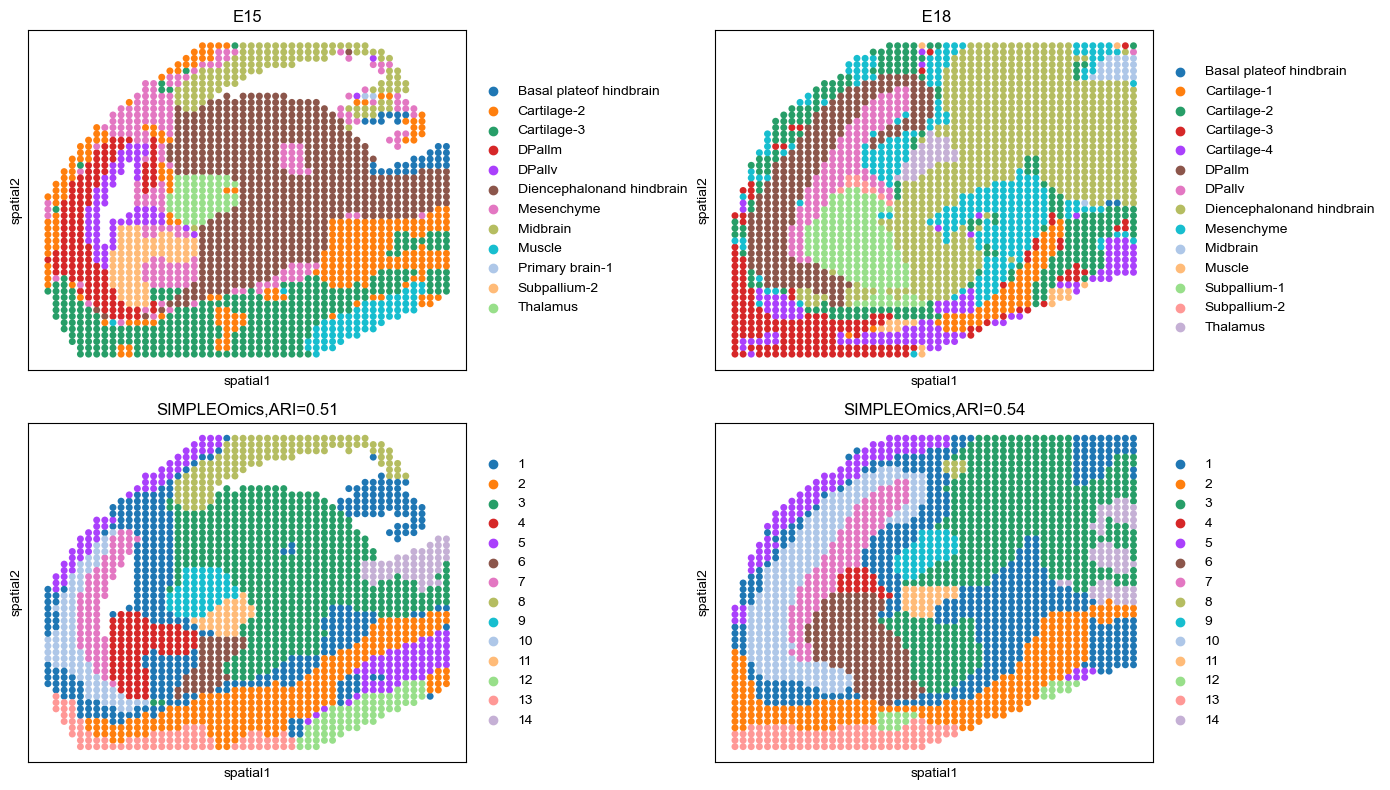

In [5]:
#visualization
import matplotlib.pyplot as plt
fig, ax_list = plt.subplots(2, 2, figsize=(14, 8))
ax_list = ax_list.flatten()
sc.pl.embedding(adata_rna[adata_rna.obs["batch"]=="Mouse_Brain_E15_S1"].copy(), basis='spatial', color='anno', ax=ax_list[0], title='E15', s=100, show=False)
sc.pl.embedding(adata_rna[adata_rna.obs["batch"]=="Mouse_Brain_E18_S1"].copy(), basis='spatial', color='anno', ax=ax_list[1], title=' E18', s=100, show=False)
sc.pl.embedding(adata_rna[adata_rna.obs["batch"]=="Mouse_Brain_E15_S1"].copy(), basis='spatial', color='mclust', ax=ax_list[2], title='SIMPLEOmics,ARI='+str(round(ari_list[0],2)), s=100, show=False)
sc.pl.embedding(adata_rna[adata_rna.obs["batch"]=="Mouse_Brain_E18_S1"].copy(), basis='spatial', color='mclust', ax=ax_list[3], title='SIMPLEOmics,ARI='+str(round(ari_list[1],2)), s=100, show=False)
plt.tight_layout(w_pad=0.3)
plt.show()